# Lab 4 – Task 1: Training & saving the models (Perceptron / Adaline)


## 1. Imports & data

In [1]:
import itertools
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from logic import (ALGORITHMS, ALL_CLASSES, ALL_FEATURES, TrainedClassifier,
                   load_birds, run_experiment)
from plotting import plot_decision_boundary, plot_learning_curve

MODELS_DIR = "models"
os.makedirs(MODELS_DIR, exist_ok=True)

birds = load_birds("birds.csv")
print("Shape:", birds.shape, "| missing values left:", int(birds.isna().sum().sum()))
birds.head()

Shape: (150, 6) | missing values left: 0


,gender,body_mass,beak_length,beak_depth,fin_length,species
0,1.0,3750,39.1,18.7,181,A
1,0.0,3800,39.5,17.4,186,A
2,0.0,3250,40.3,18.0,195,A
3,0.0,3500,39.6,17.7,186,A
4,0.0,3450,36.7,19.3,193,A


## 2. Hyper-parameters & all combinations

In [2]:
CFG = dict(eta=0.01, epochs=200, mse_threshold=0.0, use_bias=True)
N_SEEDS = 10

rows = []
for algo in ALGORITHMS:
    for cp in itertools.combinations(ALL_CLASSES, 2):
        for fp in itertools.combinations(ALL_FEATURES, 2):
            accs = [run_experiment(birds, fp, cp, algo, seed=s, **CFG).accuracy for s in range(N_SEEDS)]
            rows.append(dict(algorithm=algo, classes=f"{cp[0]} vs {cp[1]}", features=f"{fp[0]} + {fp[1]}",
                             mean_acc=np.mean(accs), std_acc=np.std(accs), _fp=fp, _cp=cp))
grid = pd.DataFrame(rows)
show_cols = ["algorithm", "classes", "features", "mean_acc", "std_acc"]
grid[show_cols].sort_values(["algorithm", "mean_acc"], ascending=[True, False]) \
    .style.format({"mean_acc": "{:.2%}", "std_acc": "{:.2%}"})

,algorithm,classes,features,mean_acc,std_acc
33,Adaline,A vs B,gender + fin_length,100.00%,0.00%
35,Adaline,A vs B,body_mass + beak_depth,100.00%,0.00%
36,Adaline,A vs B,body_mass + fin_length,100.00%,0.00%
38,Adaline,A vs B,beak_length + fin_length,100.00%,0.00%
39,Adaline,A vs B,beak_depth + fin_length,100.00%,0.00%
55,Adaline,B vs C,body_mass + beak_depth,100.00%,0.00%
59,Adaline,B vs C,beak_depth + fin_length,100.00%,0.00%
37,Adaline,A vs B,beak_length + beak_depth,99.75%,0.75%
32,Adaline,A vs B,gender + beak_depth,99.25%,1.15%
52,Adaline,B vs C,gender + beak_depth,98.75%,1.25%


### Best features for each algorithm 

In [3]:
for algo in ALGORITHMS:
    sub = grid[grid.algorithm == algo].sort_values("mean_acc", ascending=False)
    print(f"=== {algo}: top 5 combinations ===")
    print(sub[show_cols].head(5).to_string(index=False,
          formatters={"mean_acc": "{:.2%}".format, "std_acc": "{:.2%}".format}))
    print()

=== Perceptron: top 5 combinations ===
 algorithm classes                 features mean_acc std_acc
Perceptron  A vs B beak_length + fin_length   99.75%   0.75%
Perceptron  A vs B  beak_depth + fin_length   99.75%   0.75%
Perceptron  B vs C  beak_depth + fin_length   99.75%   0.75%
Perceptron  A vs B beak_length + beak_depth   99.50%   1.00%
Perceptron  A vs B      gender + fin_length   99.25%   1.60%

=== Adaline: top 5 combinations ===
algorithm classes                 features mean_acc std_acc
  Adaline  A vs B   body_mass + beak_depth  100.00%   0.00%
  Adaline  A vs B      gender + fin_length  100.00%   0.00%
  Adaline  A vs B beak_length + fin_length  100.00%   0.00%
  Adaline  A vs B  beak_depth + fin_length  100.00%   0.00%
  Adaline  A vs B   body_mass + fin_length  100.00%   0.00%



## 3. Train, visualize, **and save** the models


################ Perceptron ################


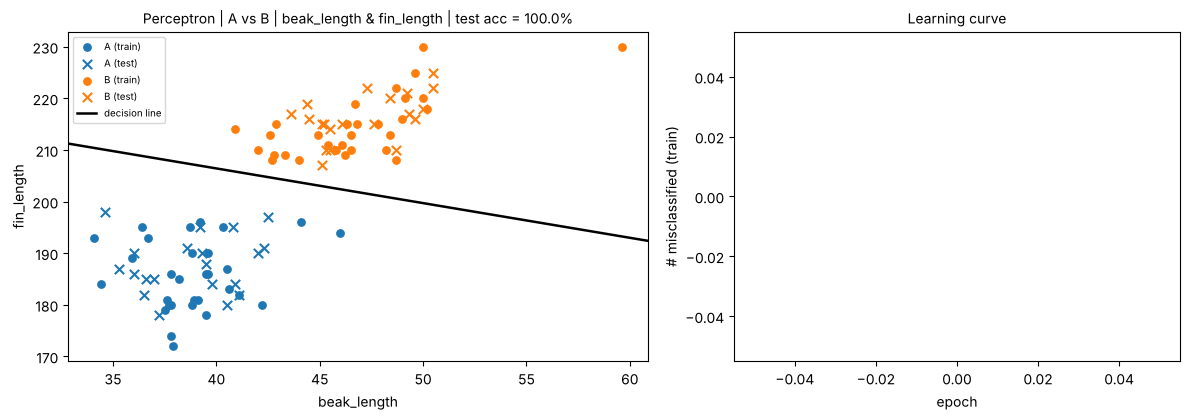

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 1
          pred A  pred B
actual A      20       0
actual B       0      20
💾 saved -> models/Perceptron_beak_length_fin_length_AB.json
----------------------------------------------------------------------


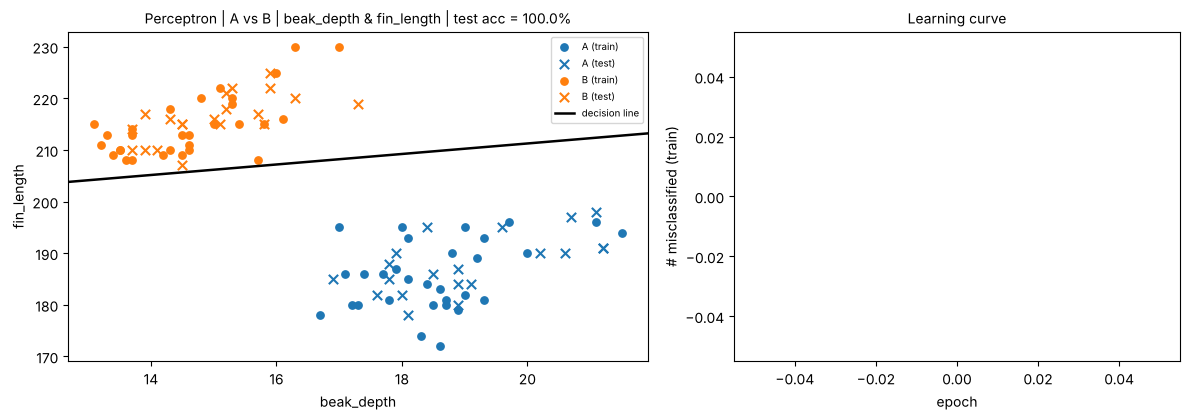

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 1
          pred A  pred B
actual A      20       0
actual B       0      20
💾 saved -> models/Perceptron_beak_depth_fin_length_AB.json
----------------------------------------------------------------------


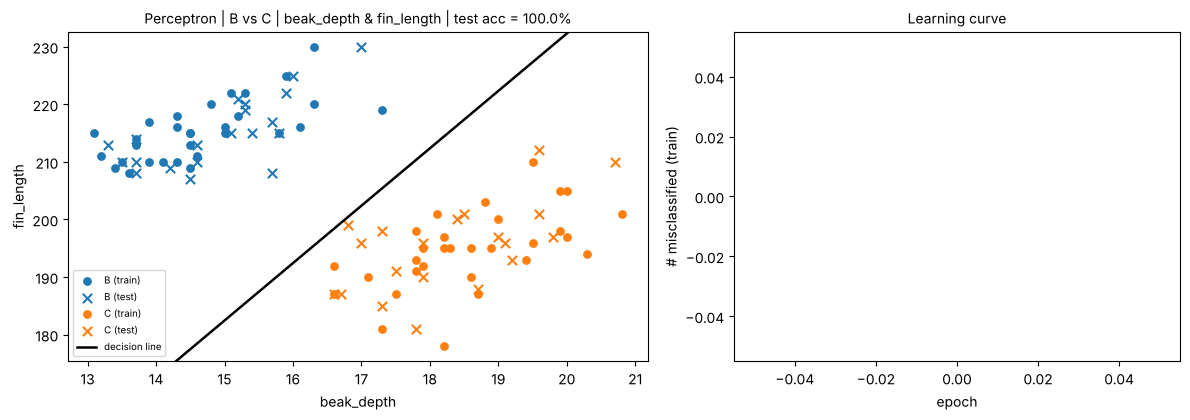

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 1
          pred B  pred C
actual B      20       0
actual C       0      20
💾 saved -> models/Perceptron_beak_depth_fin_length_BC.json
----------------------------------------------------------------------


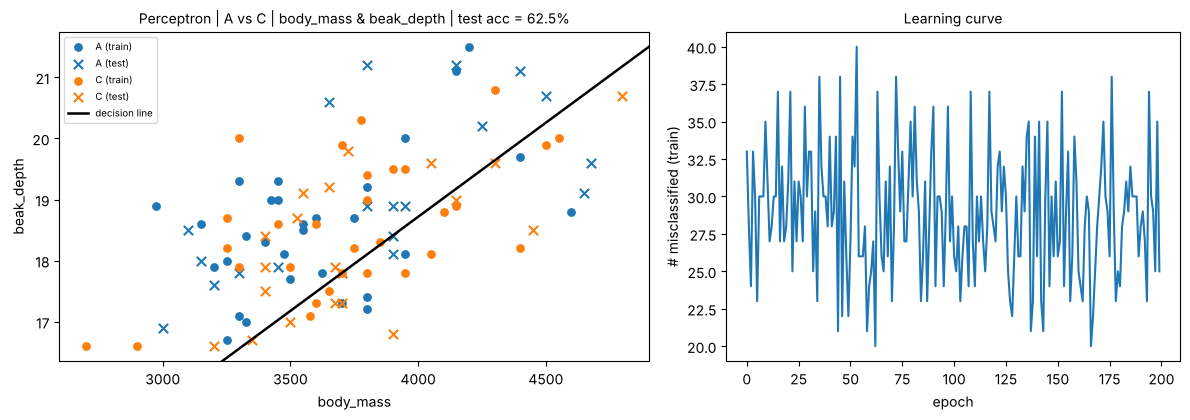

Train acc: 58.33% | Test acc (overall): 62.50% | epochs run: 200
          pred A  pred C
actual A      16       4
actual C      11       9
💾 saved -> models/Perceptron_body_mass_beak_depth_AC.json
----------------------------------------------------------------------


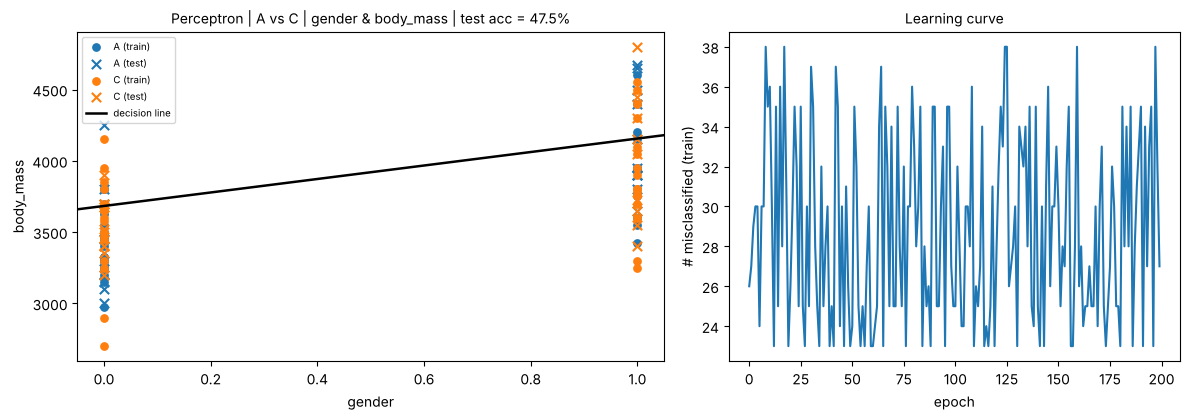

Train acc: 55.00% | Test acc (overall): 47.50% | epochs run: 200
          pred A  pred C
actual A      13       7
actual C      14       6
💾 saved -> models/Perceptron_gender_body_mass_AC.json
----------------------------------------------------------------------


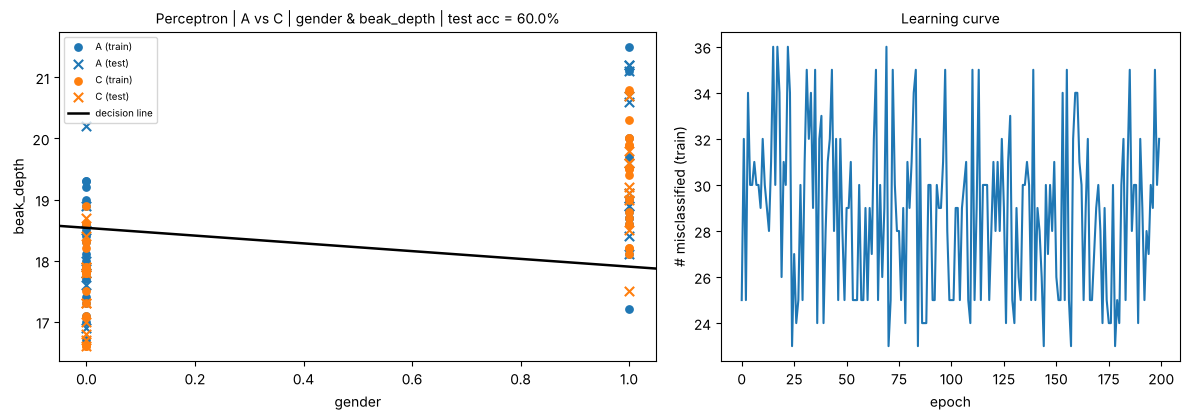

Train acc: 46.67% | Test acc (overall): 60.00% | epochs run: 200
          pred A  pred C
actual A      13       7
actual C       9      11
💾 saved -> models/Perceptron_gender_beak_depth_AC.json
----------------------------------------------------------------------

################ Adaline ################


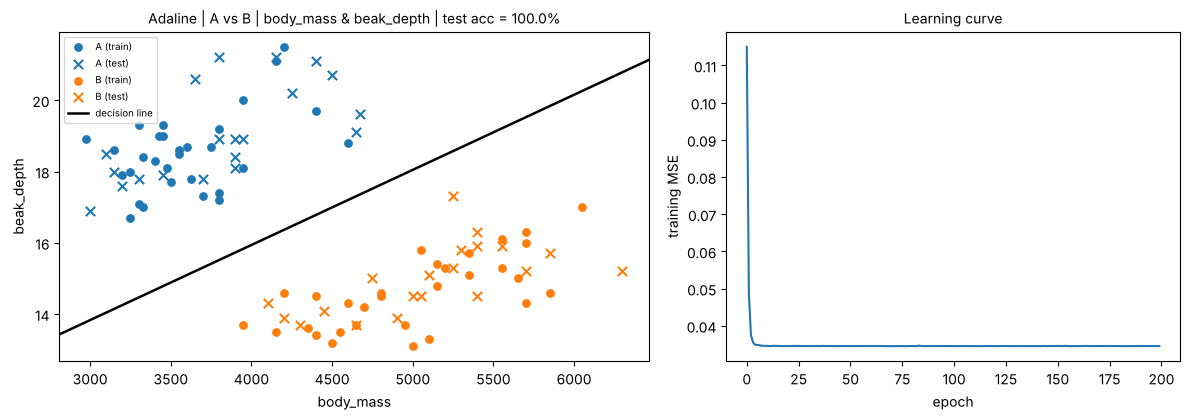

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 200
          pred A  pred B
actual A      20       0
actual B       0      20
💾 saved -> models/Adaline_body_mass_beak_depth_AB.json
----------------------------------------------------------------------


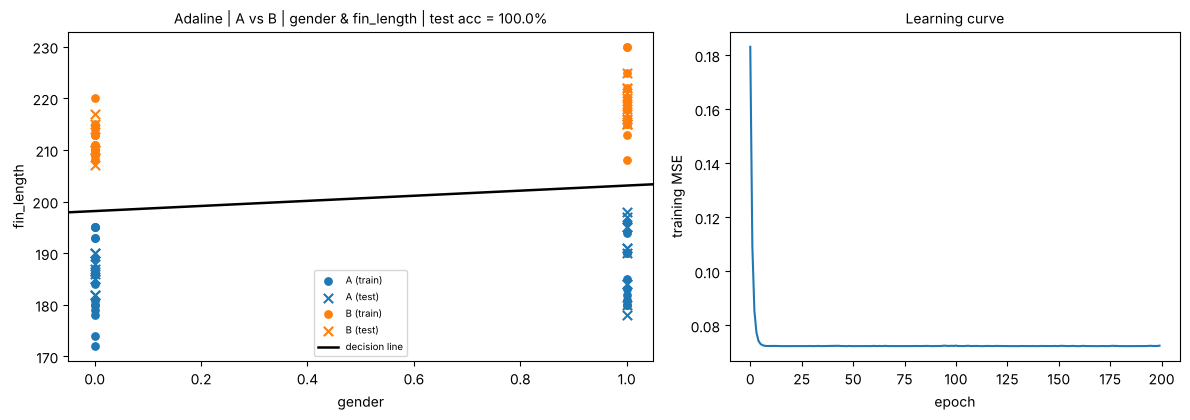

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 200
          pred A  pred B
actual A      20       0
actual B       0      20
💾 saved -> models/Adaline_gender_fin_length_AB.json
----------------------------------------------------------------------


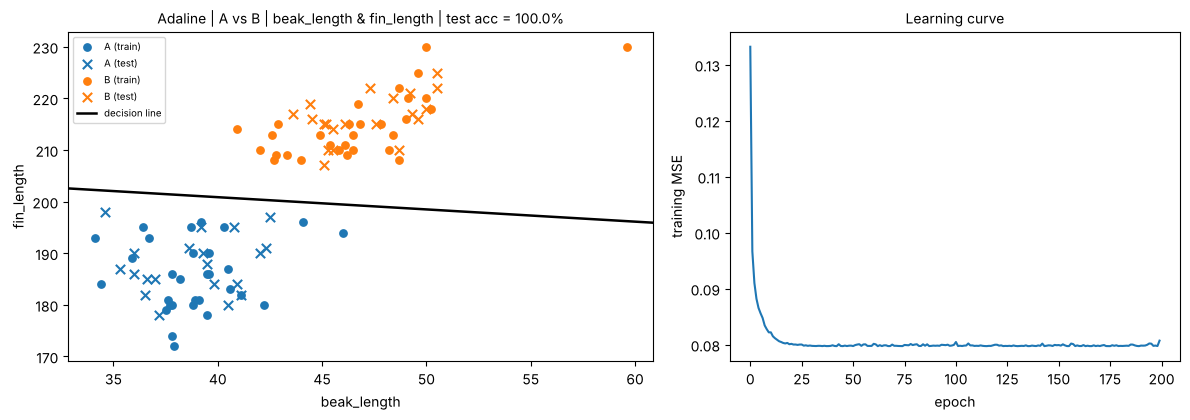

Train acc: 100.00% | Test acc (overall): 100.00% | epochs run: 200
          pred A  pred B
actual A      20       0
actual B       0      20
💾 saved -> models/Adaline_beak_length_fin_length_AB.json
----------------------------------------------------------------------


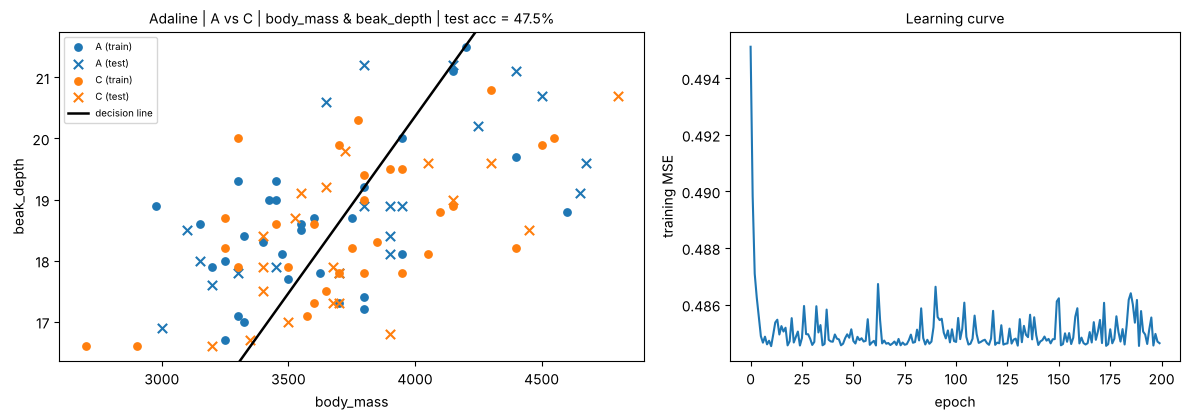

Train acc: 60.00% | Test acc (overall): 47.50% | epochs run: 200
          pred A  pred C
actual A       8      12
actual C       9      11
💾 saved -> models/Adaline_body_mass_beak_depth_AC.json
----------------------------------------------------------------------


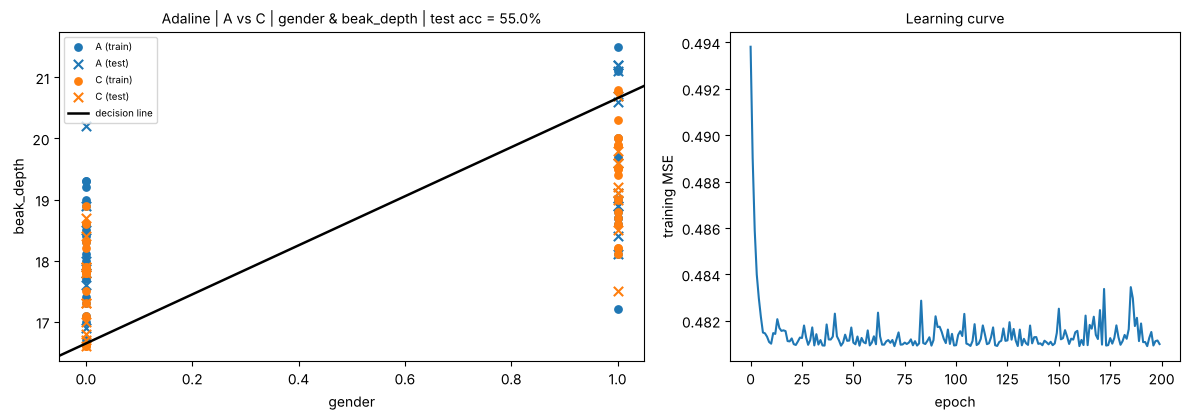

Train acc: 63.33% | Test acc (overall): 55.00% | epochs run: 200
          pred A  pred C
actual A      13       7
actual C      11       9
💾 saved -> models/Adaline_gender_beak_depth_AC.json
----------------------------------------------------------------------


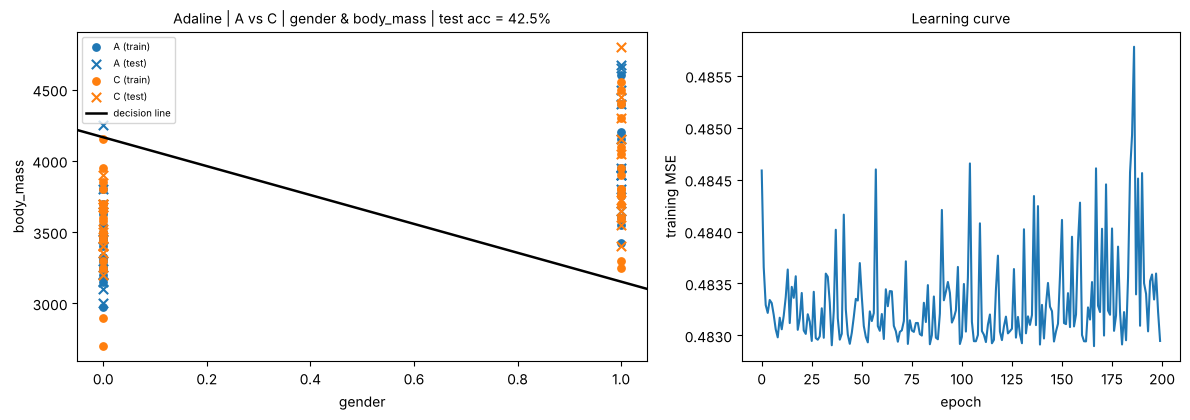

Train acc: 58.33% | Test acc (overall): 42.50% | epochs run: 200
          pred A  pred C
actual A       8      12
actual C      11       9
💾 saved -> models/Adaline_gender_body_mass_AC.json
----------------------------------------------------------------------


In [4]:
def show_and_save(algo, fp, cp, seed=0):
    res = run_experiment(birds, fp, cp, algo, seed=seed, **CFG)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.3, 1]})
    plot_decision_boundary(res, axes[0],
                           title=f"{algo} | {cp[0]} vs {cp[1]} | {fp[0]} & {fp[1]} | test acc = {res.accuracy:.1%}")
    plot_learning_curve(res, axes[1])
    plt.tight_layout(); plt.show()

    c0, c1 = cp
    print(f"Train acc: {res.train_accuracy:.2%} | Test acc (overall): {res.accuracy:.2%} | epochs run: {len(res.model.history['mse'])}")
    print(pd.DataFrame(res.cm, index=[f"actual {c0}", f"actual {c1}"], columns=[f"pred {c0}", f"pred {c1}"]))

    clf = TrainedClassifier.from_result(res)                 # <- the model to save
    clf.save(os.path.join(MODELS_DIR, clf.default_filename()))
    print(f"💾 saved -> {MODELS_DIR}/{clf.default_filename()}")
    print("-" * 70)


for algo in ALGORITHMS:
    sub = grid[grid.algorithm == algo].sort_values("mean_acc", ascending=False)
    chosen = pd.concat([sub.head(3), sub.tail(3)])
    print(f"\n################ {algo} ################")
    for _, r in chosen.iterrows():
        show_and_save(algo, r["_fp"], r["_cp"])

## 4. Check: the saved models can be loaded back (no retraining)

In [5]:
saved = sorted(f for f in os.listdir(MODELS_DIR) if f.endswith(".json"))
print(f"{len(saved)} saved models in ./{MODELS_DIR}/:")
for f in saved:
    print("  -", f)

clf = TrainedClassifier.load(os.path.join(MODELS_DIR, saved[0]))
sample = birds[birds.species == clf.classes[1]][clf.features].iloc[0].tolist()
print(f"\nLoaded '{saved[0]}' ({clf.algorithm}, test acc {clf.accuracy:.2%})")
print(f"Sample {dict(zip(clf.features, sample))} (true class {clf.classes[1]}) -> predicted {clf.classify(sample)}")

12 saved models in ./models/:
  - Adaline_beak_length_fin_length_AB.json
  - Adaline_body_mass_beak_depth_AB.json
  - Adaline_body_mass_beak_depth_AC.json
  - Adaline_gender_beak_depth_AC.json
  - Adaline_gender_body_mass_AC.json
  - Adaline_gender_fin_length_AB.json
  - Perceptron_beak_depth_fin_length_AB.json
  - Perceptron_beak_depth_fin_length_BC.json
  - Perceptron_beak_length_fin_length_AB.json
  - Perceptron_body_mass_beak_depth_AC.json
  - Perceptron_gender_beak_depth_AC.json
  - Perceptron_gender_body_mass_AC.json

Loaded 'Adaline_beak_length_fin_length_AB.json' (Adaline, test acc 100.00%)
Sample {'beak_length': 46.1, 'fin_length': 211.0} (true class B) -> predicted B
